# Étape 1 — Valider l'outil de latence : respiration ↔ cœur (RSA)

Idée : l'arythmie sinusale respiratoire (RSA) est un couplage connu — le cœur accélère à l'inspiration et ralentit à l'expiration. Si notre outil ne retrouve pas ce couplage (et un délai plausible), le problème vient du pipeline, pas de la biologie.

**Sous-étapes**
1. **Charger et inspecter** ECG + Resp sur les périodes de repos du sample (P001, day-1). ✅
2. **Respiration** : filtrage, fréquence respiratoire. ✅
3. **ECG** : détection des pics R, contrôle visuel, série de fréquence cardiaque (HR) instantanée rééchantillonnée. ✅
4. **Couplage attendu** : spectre de HR et cohérence Resp–HR (pic à la fréquence respiratoire ?). ✅
5. **Délai** : appliquer `latence()` Resp → HR (attention : signal périodique → `max_lag` < ½ période respiratoire). ← *ici*
6. **Contrôles** : décalage artificiel connu (l'outil doit le retrouver), surrogates (décalage circulaire), stabilité par fenêtres, CURATED vs PREPROCESSED.
7. **Bilan** : figer les fonctions validées dans `latence/` (module .py) pour les étapes 2–3.

In [34]:
from scipy.signal import correlate, correlation_lags
import numpy as np

In [49]:
def latence(x, y, fs, max_lag_s=3, sign=None):
    """latence (s) that maximize the correlation between x and y.

    Lag > 0 : y est en retard sur x.
    sign : None = plus grand |corrélation| (comportement d'origine),
           +1 = plus grande corrélation positive, -1 = plus grande corrélation négative.
    """

    x = (x - x.mean()) / x.std()
    y = (y - y.mean()) / y.std()
    c = correlate(y, x, mode="full") / len(x)
    lags = correlation_lags(len(y), len(x), mode="full") / fs
    keep = np.abs(lags) <= max_lag_s
    score = np.abs(c[keep]) if sign is None else sign * c[keep]
    best = np.argmax(score)
    return lags[keep][best], c[keep][best] 

## 1.1 — Charger et inspecter

Périodes de repos disponibles dans le sample (d'après `P001_day-1_metadata.json`) :
- segment **resting-state** (95 s) : 30 s repos sans clignement, puis 60 s yeux fermés ;
- segment **artefact** : 2 × 60 s repos yeux ouverts (au début et à la fin ; entre les deux, mouvements instruits à exclure).

Le segment emotion-video n'est pas dans le sample.

In [36]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "latence" else Path.cwd()
sys.path.insert(0, str(ROOT / "starting_notebooks"))
from bdf_loader import load_bdf

DATA = ROOT / "sample"          # dataset en lecture seule
VERSION = "CURATED"             # signaux bruts : on maîtrise nous-mêmes le filtrage (PREPROCESSED modifie aussi ECG/Resp, traitement non documenté)
SUBJ, DAY = "P001", 1
FS = 1000.0

In [37]:
def load_physio(task, version=VERSION, subj=SUBJ, day=DAY, data=DATA):
    """Charge ECG + Resp d'un segment. Retourne un DataFrame (time_s, ECG, Resp)."""
    bdf = data / version / subj / f"{subj}_day-{day}_task-{task}_multimodal.bdf"
    _, signals, channels = load_bdf(bdf)
    return signals[["time_s", "ECG", "Resp"]].copy(), channels

def task_windows(task, subj=SUBJ, day=DAY, data=DATA, version=VERSION):
    """Fenêtres des événements (en s, relatives au segment) d'après le metadata."""
    meta = json.loads((data / version / subj / f"{subj}_day-{day}_metadata.json").read_text())
    seg = meta["dataset_export"]["segments"][task]
    t0, dur = seg["metadata_time_origin_s"], seg["duration_s"]
    out = []
    for ev in meta["events"]:
        on = ev["onset_s"] - t0
        if 0 <= on < dur:
            off = min(on + ev["duration_s"], dur)
            out.append((round(on, 3), round(off, 3), ev.get("instruction_text")))
    return out

for task in ["resting-state", "artefact"]:
    print(task, task_windows(task))

resting-state [(0.0, 30.0, 'repos calme sans clignements des yeux, ni mouvements'), (35.078, 95.078, 'repos calme yeux fermes')]
artefact [(9.928, 69.928, 'repos calme yeux ouverts'), (75.0, 80.0, 'cligner des yeux'), (85.082, 90.082, 'sans bouger la tete, deplacer les yeux de droite a gauche'), (95.161, 100.161, 'sans bouger la tete, deplacer les yeux de haut en bas'), (105.235, 110.235, 'tourner la tete de gauche a droite.'), (115.31, 120.31, 'incliner la tete de haut en bas'), (125.392, 130.392, 'serrer la machoire'), (135.463, 140.463, 'deglutir a repetition'), (145.533, 205.533, 'repos calme yeux ouverts')]


In [38]:
rest, ch = load_physio("resting-state")
art, _ = load_physio("artefact")
print(ch.loc[ch.bdf_label.isin(["ECG", "Resp"]), ["bdf_label", "header_unit", "header_rate_hz"]])
for name, df in [("resting-state", rest), ("artefact", art)]:
    print(f"{name}: {len(df)/FS:.1f} s, NaN ECG={df.ECG.isna().sum()}, NaN Resp={df.Resp.isna().sum()}")

Channel metadata: P001_day-1_task-resting-state_multimodal.record_map
Gaze: stored 166 Hz, effective 166.358 Hz, onset 0.005 s
Channel metadata: P001_day-1_task-artefact_multimodal.record_map
Gaze: stored 166 Hz, effective 166.358 Hz, onset 0.002 s
   bdf_label header_unit  header_rate_hz
64       ECG          mV          1000.0
65      Resp          AU          1000.0
resting-state: 95.1 s, NaN ECG=0, NaN Resp=0
artefact: 212.3 s, NaN ECG=0, NaN Resp=0


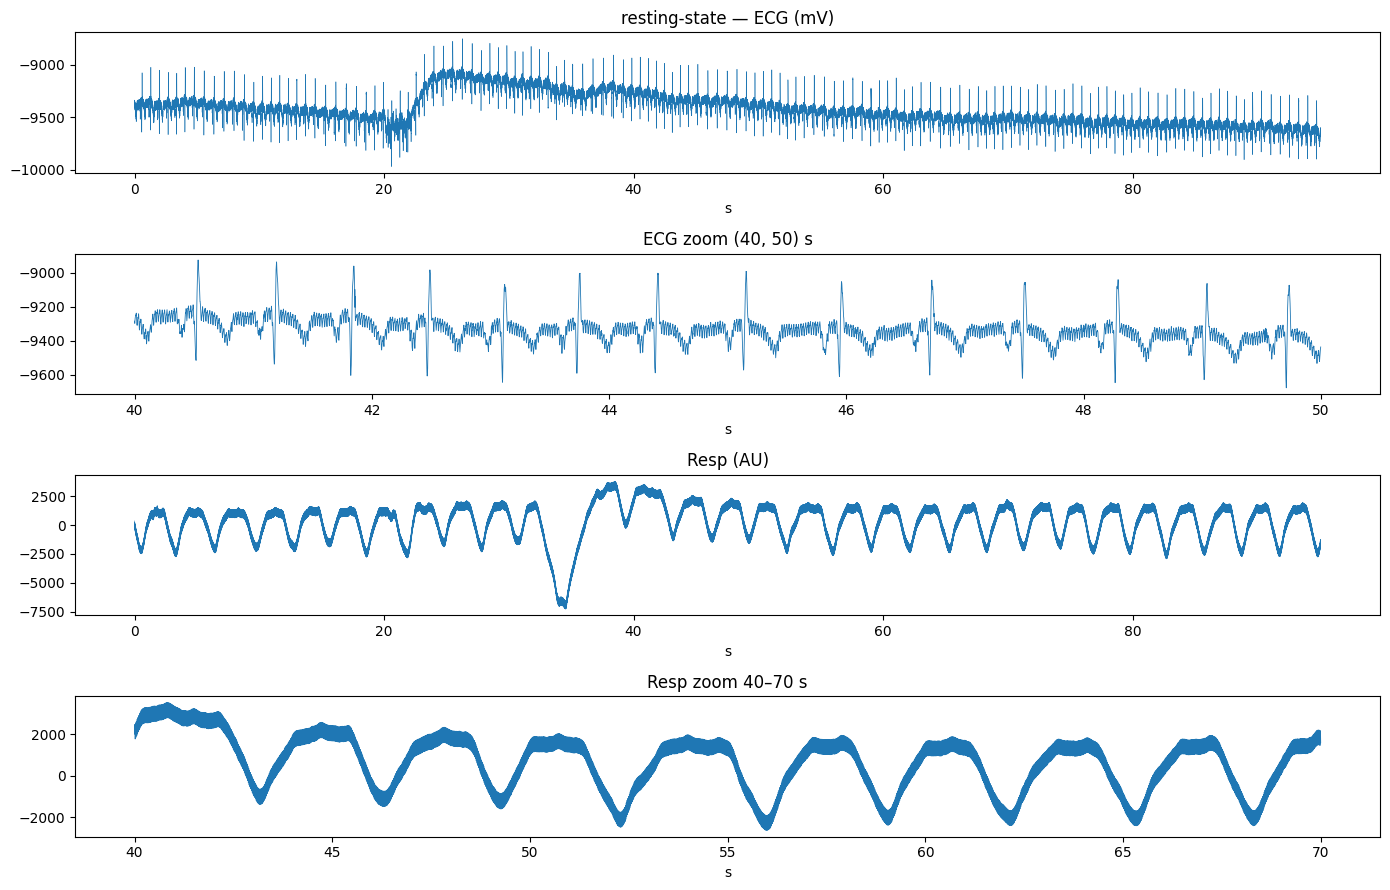

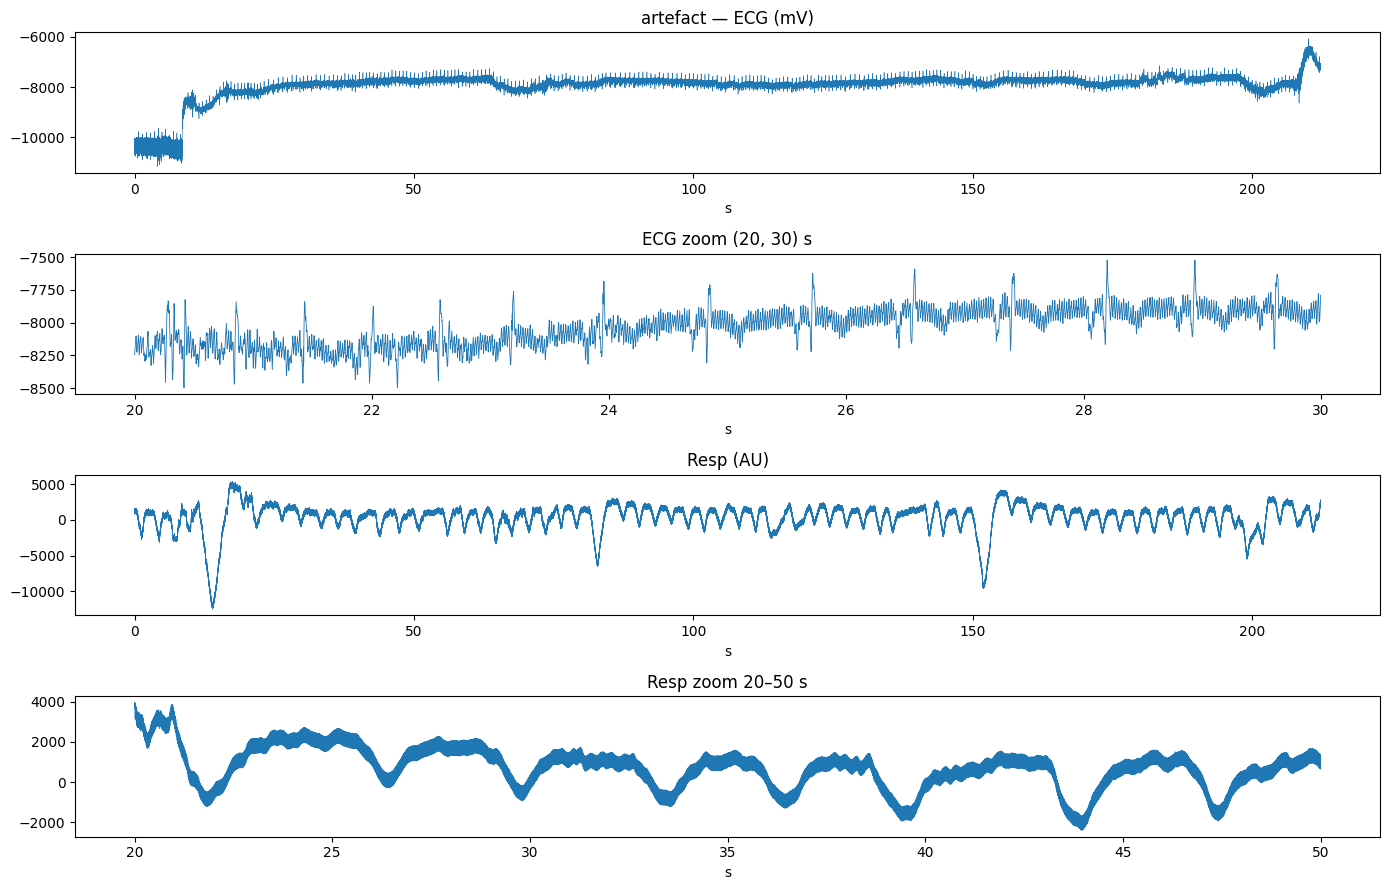

In [39]:
def plot_raw(df, title, zoom=(40, 50)):
    t = df.time_s.to_numpy()
    fig, ax = plt.subplots(4, 1, figsize=(14, 9))
    z = (t >= zoom[0]) & (t < zoom[1])
    ax[0].plot(t, df.ECG, lw=.4); ax[0].set_title(f"{title} — ECG (mV)")
    ax[1].plot(t[z], df.ECG[z], lw=.6); ax[1].set_title(f"ECG zoom {zoom} s")
    ax[2].plot(t, df.Resp, lw=.4); ax[2].set_title("Resp (AU)")
    z2 = (t >= zoom[0]) & (t < zoom[0] + 30)
    ax[3].plot(t[z2], df.Resp[z2], lw=.6); ax[3].set_title(f"Resp zoom {zoom[0]}–{zoom[0]+30} s")
    for a in ax: a.set_xlabel("s")
    plt.tight_layout(); plt.show()

plot_raw(rest, "resting-state")
plot_raw(art, "artefact", zoom=(20, 30))

**Constats (P001, resting-state)** — à vérifier sur ta figure :
- **ECG** : pics R nets et positifs (~85 bpm, RR ≈ 0,7 s) ; dérive de ligne de base (saut vers 22 s) et bruit secteur 50 Hz visible → passe-haut + coupe-bande / passe-bas avant détection des R.
- **Resp** : oscillation propre, période ≈ 3,5 s (~17 cycles/min, ≈ 0,28 Hz) ; grosse inspiration/soupir vers 35 s (transition vers « yeux fermés ») ; bruit haute fréquence (trace épaisse) → passe-bas ~1 Hz.
- Conséquence pour le délai : avec une période de ~3,5 s, la cross-corrélation est ambiguë au-delà de ±1,75 s → limiter `max_lag_s` en conséquence (sous-étape 5).

➡️ Prochaine sous-étape : **1.2 Respiration**.

## 1.2 — Respiration

1. **Filtrer** : passe-bande 0,05–1 Hz (la respiration au repos est entre 0,1 et 0,5 Hz), Butterworth appliqué avec `sosfiltfilt` → **phase nulle**, donc aucun décalage temporel introduit (essentiel pour mesurer des latences).
2. **Détecter les cycles** : pics et creux avec `find_peaks` (au moins 1,5 s entre deux pics).
3. **Fréquence respiratoire** : période médiane entre pics (plus robuste que le pic du spectre, qui se fait piéger par les grandes inspirations).
4. **Polarité** : la ceinture peut être montée « à l'envers ». On compare la durée des phases montante et descendante : l'inspiration est normalement plus courte que l'expiration.

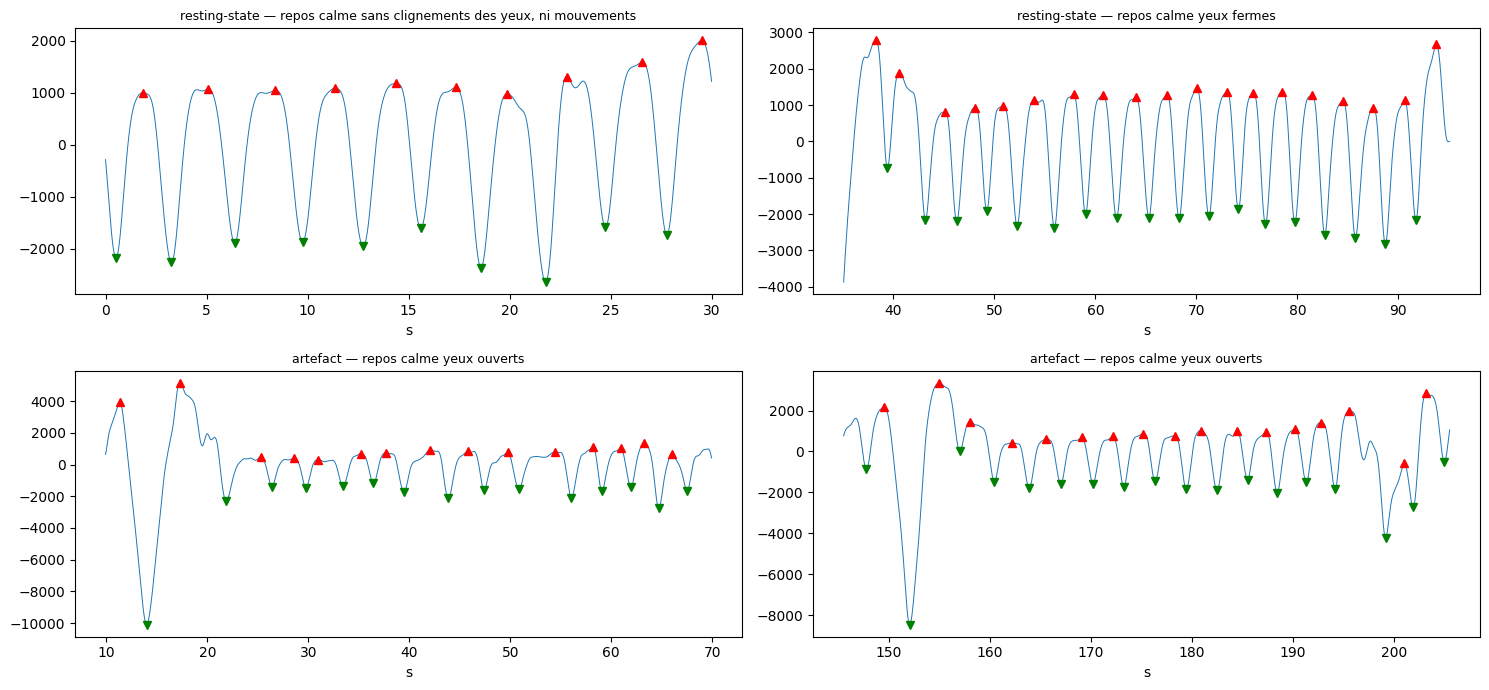

,task,fenêtre,consigne,n_cycles,période_méd_s,resp_par_min,montée_s,descente_s
0,resting-state,0-30 s,"repos calme sans clignements des yeux, ni mouv...",9,2.97,20.17,1.68,1.34
1,resting-state,35-95 s,repos calme yeux fermes,18,3.00,19.98,1.77,1.22
2,artefact,10-70 s,repos calme yeux ouverts,14,3.76,15.96,2.02,1.54
3,artefact,146-206 s,repos calme yeux ouverts,16,3.06,19.63,1.78,1.44


In [40]:
from scipy.signal import butter, sosfiltfilt, find_peaks

def bandpass(x, lo, hi, fs=FS, order=2):
    """Filtre passe-bande Butterworth à phase nulle (aller-retour)."""
    sos = butter(order, [lo, hi], btype="band", fs=fs, output="sos")
    return sosfiltfilt(sos, x)

def breath_cycles(x, fs=FS):
    """Pics et creux respiratoires d'un signal filtré."""
    prom = 0.6 * np.std(x)
    peaks, _ = find_peaks(x, distance=int(1.5 * fs), prominence=prom)
    troughs, _ = find_peaks(-x, distance=int(1.5 * fs), prominence=prom)
    return peaks, troughs

# On filtre le segment entier (évite les effets de bord), puis on découpe les fenêtres de repos
resp_f = {task: bandpass(df.Resp.to_numpy(), 0.05, 1.0) for task, df in [("resting-state", rest), ("artefact", art)]}

rows = []
fig, axs = plt.subplots(2, 2, figsize=(15, 7))
for ax, (task, (on, off, txt)) in zip(axs.flat, [(task, w) for task in resp_f for w in task_windows(task) if w[2].startswith("repos")]):
    a, b = int(on * FS), int(off * FS)
    x, t = resp_f[task][a:b], np.arange(a, b) / FS
    pk, tr = breath_cycles(x)
    period = np.diff(pk) / FS
    rise = [(pk[pk > q][0] - q) / FS for q in tr if (pk > q).any()]   # creux -> pic suivant
    fall = [(tr[tr > q][0] - q) / FS for q in pk if (tr > q).any()]   # pic -> creux suivant
    rows.append({"task": task, "fenêtre": f"{on:.0f}-{off:.0f} s", "consigne": txt,
                 "n_cycles": len(period), "période_méd_s": np.median(period),
                 "resp_par_min": 60 / np.median(period),
                 "montée_s": np.median(rise), "descente_s": np.median(fall)})
    ax.plot(t, x, lw=.7); ax.plot(t[pk], x[pk], "r^"); ax.plot(t[tr], x[tr], "gv")
    ax.set_title(f"{task} — {txt}", fontsize=9); ax.set_xlabel("s")
plt.tight_layout(); plt.show()
resp_stats = pd.DataFrame(rows).round(2)
resp_stats

**Constats (P001)** — à vérifier sur ta figure :
- **Fréquence** : période médiane ≈ 3 s (~20 respirations/min) sur 3 fenêtres ; 3,8 s (~16/min) sur la 1re fenêtre de l'artefact. Fréquence respiratoire ≈ 0,26–0,33 Hz.
- **Grandes inspirations** (soupirs) au début de chaque fenêtre ou presque (≈ 14 s et 152 s dans artefact, 35 s et 93 s dans resting-state). Elles écrasent le spectre (d'où le choix de la période médiane). On les garde pour l'instant : elles provoquent souvent une forte réponse cardiaque, utile pour l'étape 1.
- **Polarité probablement inversée** — trois indices concordants :
  1. les soupirs (inspirations profondes) partent **vers le bas** ;
  2. le plateau (pause de fin d'expiration, poumons « vides ») est **en haut** ;
  3. la phase descendante est plus courte que la montante, or l'inspiration est plus courte que l'expiration.

  → **descente = inspiration**. On travaillera avec `-Resp` pour que « haut = inspiration ». À revérifier pour chaque participant (dépend du montage de la ceinture).

➡️ Prochaine sous-étape : **1.3 ECG** (pics R, fréquence cardiaque instantanée).

In [41]:
# Convention pour la suite : signal positif = inspiration
resp_insp = {task: -x for task, x in resp_f.items()}

## 1.3 — ECG : pics R et fréquence cardiaque

0. **Polarité** : selon le placement des électrodes, les pics R peuvent pointer vers le bas. `ecg_polarity` compare l'amplitude des maximums et des minimums autour des battements et le signal est inversé si besoin. Sans ça, `find_peaks` accrocherait l'onde Q/S retournée : RR plausibles, mais instants décalés (−23 ms sur P001 inversé) → erreur silencieuse pour le HEP.
1. **Détection** : passe-bande 5–30 Hz (garde le complexe QRS, retire la dérive et le 50 Hz), puis `find_peaks` avec au moins 0,33 s entre deux battements (max ~180 bpm) et un seuil à 40 % de l'amplitude typique des R.
2. **Affinage** : le filtre déforme légèrement le QRS, donc on replace chaque pic sur le maximum de l'ECG brut (juste débarrassé de sa dérive) à ±30 ms. Précision de 1 ms, utile aussi pour le HEP (étape 2).
3. **Contrôle qualité** : un intervalle RR qui s'écarte de plus de 20 % de la médiane des battements voisins est marqué comme suspect (pic raté ou faux pic).
4. **Fréquence cardiaque instantanée** : HR = 60 / RR, placée au temps du 2e battement, puis interpolée sur une grille régulière à 4 Hz (pour pouvoir la comparer à la respiration).
   Les RR suspects sont retirés avant l'interpolation.

In [42]:
FS_HR = 4.0  # Hz, grille régulière pour HR et Resp

def ecg_polarity(ecg, fs=FS):
    """+1 si les pics R pointent vers le haut, -1 s'ils pointent vers le bas.

    On repère les battements sur |ECG filtré| (indépendant du signe), puis on compare,
    autour de chaque battement (±60 ms), le maximum et le minimum de l'ECG sans dérive.
    Retourne (polarité, ratio max/|min| médian). Ratio proche de 1 = ambigu → vérifier à l'œil.
    """
    e = np.abs(bandpass(ecg, 5, 30, fs))
    beats, _ = find_peaks(e, distance=int(0.33 * fs), height=0.4 * np.percentile(e, 99))
    raw = bandpass(ecg, 0.5, 45, fs)
    w = int(0.06 * fs)
    beats = beats[(beats > w) & (beats < len(raw) - w)]
    ratio = np.median([raw[b - w:b + w].max() for b in beats]) / np.median([-raw[b - w:b + w].min() for b in beats])
    return (1 if ratio >= 1 else -1), ratio

def r_peaks(ecg, fs=FS):
    """Indices des pics R (échantillons). Le signal est remis à l'endroit si besoin."""
    pol, ratio = ecg_polarity(ecg, fs)
    if 0.8 < ratio < 1.25:
        print(f"⚠️ polarité ECG ambiguë (ratio max/|min| = {ratio:.2f}) : vérifier le battement moyen")
    ecg = pol * ecg
    e = bandpass(ecg, 5, 30, fs)
    pk, _ = find_peaks(e, distance=int(0.33 * fs), height=0.4 * np.percentile(e, 99))
    raw = bandpass(ecg, 0.5, 45, fs)              # ECG brut sans dérive
    w = int(0.03 * fs)
    starts = np.maximum(pk - w, 0)                 # même début pour découper et pour ré-indexer
    return np.array([a + np.argmax(raw[a:p + w]) for a, p in zip(starts, pk)])

def rr_suspects(pk, fs=FS, tol=0.2):
    """Booléen par intervalle RR : True si écart > tol à la médiane locale (9 battements)."""
    rr = np.diff(pk) / fs
    med = pd.Series(rr).rolling(9, center=True, min_periods=1).median().to_numpy()
    return np.abs(rr - med) / med > tol

def hr_series(pk, n_samples, fs=FS, fs_out=FS_HR):
    """HR instantanée (bpm) interpolée sur une grille régulière couvrant le segment."""
    rr = np.diff(pk) / fs
    ok = ~rr_suspects(pk, fs)
    t_beat, hr = pk[1:][ok] / fs, 60 / rr[ok]
    t = np.arange(0, n_samples / fs, 1 / fs_out)
    return t, np.interp(t, t_beat, hr)

rpk, hr = {}, {}
for task, df in [("resting-state", rest), ("artefact", art)]:
    ecg = df.ECG.to_numpy()
    pol, ratio = ecg_polarity(ecg)
    print(f"{task}: polarité {'+' if pol > 0 else '−'} (ratio max/|min| = {ratio:.2f})")
    rpk[task] = r_peaks(ecg)
    hr[task] = hr_series(rpk[task], len(ecg))
    bad = rr_suspects(rpk[task])
    print(f"{task}: {len(rpk[task])} battements, HR moyenne {60 / np.mean(np.diff(rpk[task]) / FS):.0f} bpm, "
          f"RR suspects : {bad.sum()} à t = {np.round(rpk[task][1:][bad] / FS, 1)} s")

resting-state: polarité + (ratio max/|min| = 1.39)
resting-state: 133 battements, HR moyenne 84 bpm, RR suspects : 0 à t = [] s
artefact: polarité + (ratio max/|min| = 1.41)
artefact: 305 battements, HR moyenne 86 bpm, RR suspects : 5 à t = [  8.6   9.6 208.8 209.2 210.8] s


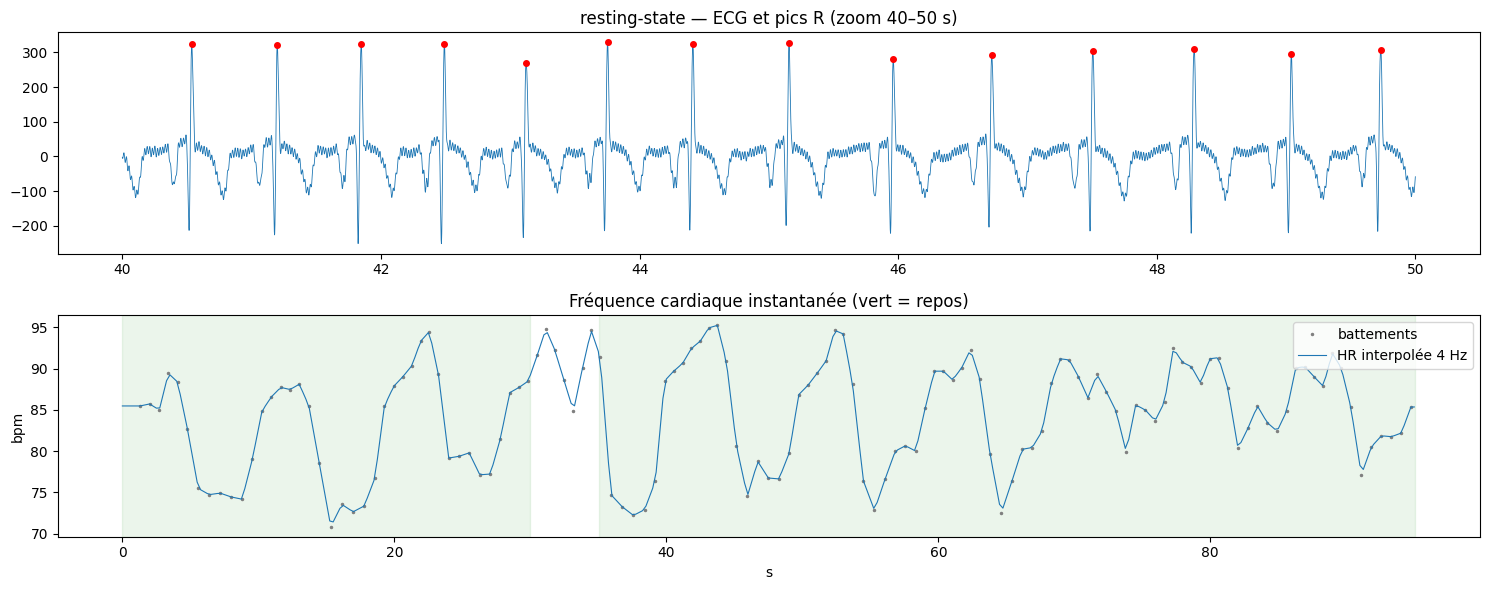

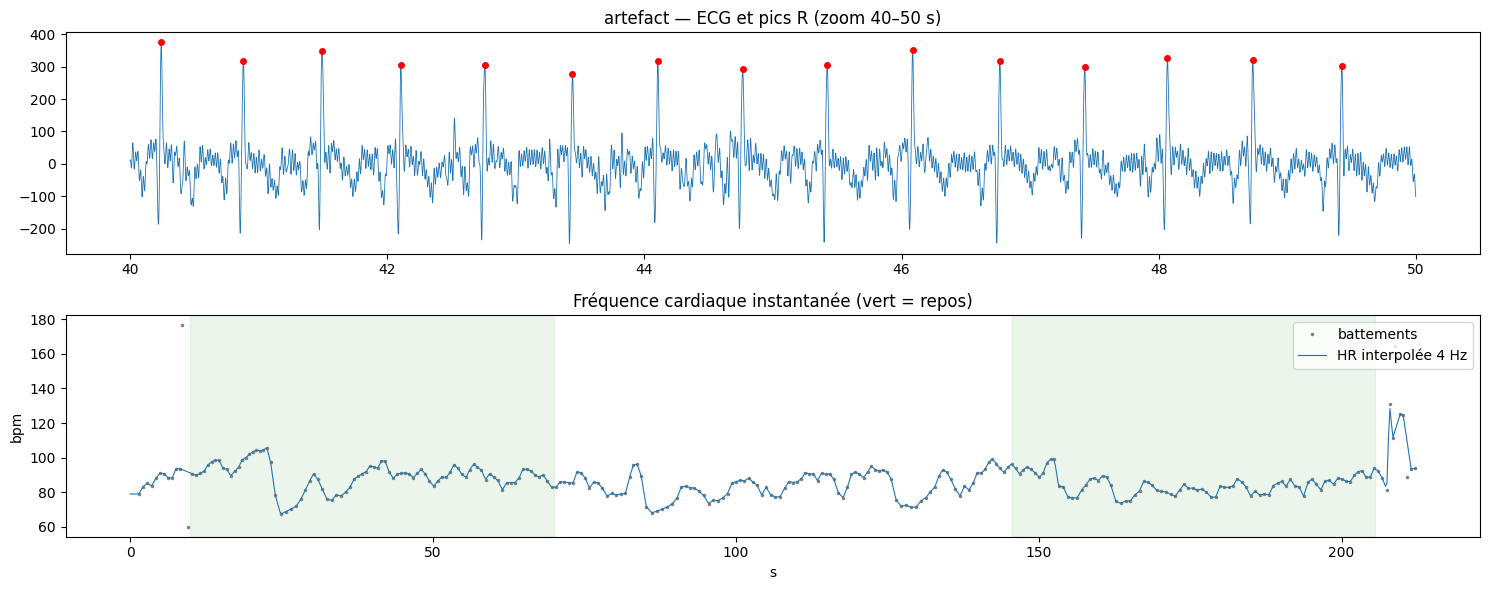

In [43]:
# Contrôle visuel : pics R sur l'ECG (zoom 10 s) + HR instantanée avec les fenêtres de repos
for task, df in [("resting-state", rest), ("artefact", art)]:
    ecg = bandpass(df.ECG.to_numpy(), 0.5, 45)
    t = np.arange(len(ecg)) / FS
    pk = rpk[task]
    fig, ax = plt.subplots(2, 1, figsize=(15, 6))
    z = (t >= 40) & (t < 50); zp = pk[(pk / FS >= 40) & (pk / FS < 50)]
    ax[0].plot(t[z], ecg[z], lw=.6); ax[0].plot(zp / FS, ecg[zp], "r.", ms=8)
    ax[0].set_title(f"{task} — ECG et pics R (zoom 40–50 s)")
    th, h = hr[task]
    ax[1].plot(pk[1:] / FS, 60 / (np.diff(pk) / FS), ".", ms=3, color="grey", label="battements")
    ax[1].plot(th, h, lw=.8, label="HR interpolée 4 Hz")
    for on, off, txt in task_windows(task):
        if txt.startswith("repos"):
            ax[1].axvspan(on, off, color="green", alpha=.08)
    ax[1].set_ylabel("bpm"); ax[1].set_xlabel("s"); ax[1].legend(loc="upper right")
    ax[1].set_title("Fréquence cardiaque instantanée (vert = repos)")
    plt.tight_layout(); plt.show()

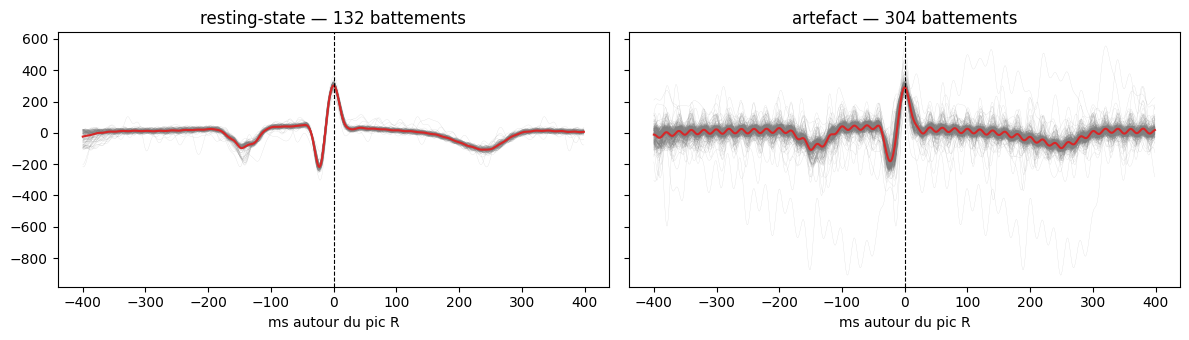

In [44]:
# Battement moyen centré sur les R détectés : le R doit être un pic net, positif, exactement à 0 ms
fig, axs = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, (task, df) in zip(axs, [("resting-state", rest), ("artefact", art)]):
    pol, _ = ecg_polarity(df.ECG.to_numpy())
    ecg = pol * bandpass(df.ECG.to_numpy(), 0.5, 45)
    w = int(0.4 * FS); lags = np.arange(-w, w) / FS * 1000
    pk = rpk[task][(rpk[task] > w) & (rpk[task] < len(ecg) - w)]
    beats = np.array([ecg[p - w:p + w] for p in pk])
    ax.plot(lags, beats.T, color="grey", lw=.2, alpha=.3)
    ax.plot(lags, beats.mean(0), color="C3", lw=1.5)
    ax.axvline(0, ls="--", color="k", lw=.8)
    ax.set_title(f"{task} — {len(pk)} battements"); ax.set_xlabel("ms autour du pic R")
plt.tight_layout(); plt.show()

**Constats (P001)** — à vérifier sur ta figure :
- **Polarité** : positive dans les deux segments (ratio max/|min| ≈ 1,4), aucune inversion.
- **Pics R** : tous détectés proprement sur les zooms ; 133 battements en resting-state, ~85 bpm. Le battement moyen a son R à 0 ms.
- **RR suspects** : 0 en resting-state ; quelques-uns dans artefact vers 8 s et 208–210 s, **en dehors des fenêtres de repos** (10–70 s et 146–206 s) → aucun impact sur l'étape 1.
- **HR oscille fortement** (~75 à ~95 bpm) mais surtout **lentement** (période ~7–8 s, ≈ 0,12 Hz) : ce n'est pas la RSA, la respiration a une période de ~3 s. La RSA, si elle est là, est une ondulation plus petite superposée → à vérifier en 1.4 dans le spectre.

➡️ Prochaine sous-étape : **1.4 Couplage attendu** (spectre de HR, cohérence Resp–HR).

## 1.4 — Couplage attendu : spectre de HR et cohérence Resp–HR

Avant de mesurer un délai, on vérifie qu'il y a bien un couplage à mesurer : si la RSA est là, la fréquence cardiaque doit osciller **à la fréquence respiratoire**.

- **Mise sur la même grille** : HR est à 4 Hz (1.3), Resp à 1000 Hz → on lit Resp aux mêmes instants que HR. Pas de risque de repliement : Resp est déjà filtrée sous 1 Hz (1.2), bien en dessous de la limite de Nyquist à 2 Hz.
- **Spectre de HR** (Welch) : on cherche un pic vers 0,26–0,33 Hz (fréquence respiratoire trouvée en 1.2). Attention : HR contient aussi des oscillations lentes (< 0,15 Hz) souvent plus puissantes que la RSA → on cherche le pic dans la bande 0,15–0,5 Hz.
- **Cohérence Resp–HR** : entre 0 et 1, pour chaque fréquence, à quel point les deux signaux oscillent ensemble avec un décalage de phase stable. Proche de 1 à la fréquence respiratoire = couplage fort. Elle est calculée par Welch : il faut **plusieurs segments** pour qu'elle ait un sens (avec un seul segment elle vaut 1 partout). D'où `nperseg` = 16 s par défaut : ~0,06 Hz de résolution et 6 segments (avec 50 % de recouvrement) sur une fenêtre de 60 s, mais seulement 2 sur 30 s.
- **Filtrage de HR** (`hr_fast`, 0,15–1 Hz) : sans lui, le pic lent de HR (~0,12 Hz) déborde sur ses voisins et `band_peak` tombe à côté du pic respiratoire.
- La **phase** de l'interspectre au pic donne déjà une idée du délai (Δt = phase / (2π f)), qu'on comparera à `latence()` en 1.5.

In [45]:
from scipy.signal import welch, coherence, csd

def on_grid(x, t_grid, fs=FS):
    """Valeurs du signal x (échantillonné à fs depuis t=0) aux instants t_grid (s)."""
    return np.interp(t_grid, np.arange(len(x)) / fs, x)

def hr_fast(h, lo=0.15, hi=1.0, fs=FS_HR):
    """Garde seulement les oscillations rapides de HR (bande de la RSA).

    Retire les oscillations lentes (< 0,15 Hz) qui dominent HR et dont la « traîne »
    spectrale masque le pic respiratoire. À appliquer sur HR du segment entier
    (avant découpage) pour éviter les effets de bord. Phase nulle → aucun décalage."""
    return bandpass(h, lo, hi, fs=fs)

def crop(t, x, on, off):
    """Morceau de x (et de son temps t) compris dans [on, off[ secondes."""
    keep = (t >= on) & (t < off)
    return t[keep], x[keep]

def spectrum(x, fs=FS_HR, nperseg_s=16):
    """Densité spectrale de puissance (Welch), tendance linéaire retirée par segment."""
    n = min(int(nperseg_s * fs), len(x))
    return welch(x, fs=fs, nperseg=n, detrend="linear")

def band_peak(f, p, lo=0.15, hi=0.5):
    """Fréquence et valeur du maximum de p dans la bande [lo, hi] Hz.

    Par défaut : bande « haute fréquence » de la variabilité cardiaque (≈ 0,15–0,4 Hz),
    celle de la RSA. En dessous (< 0,15 Hz) dominent des oscillations lentes de HR
    (ondes de Mayer, réponses aux soupirs) qui écraseraient le pic respiratoire."""
    band = (f >= lo) & (f <= hi)
    i = np.argmax(p[band])
    return f[band][i], p[band][i]

def resp_hr_coherence(resp, hr, fs=FS_HR, nperseg_s=16):
    """Cohérence Resp–HR et phase de l'interspectre, par fréquence.

    Retourne (f, coh, phase) ; phase en radians, > 0 si HR est en retard sur Resp
    (convention : délai = phase / (2π f) secondes).
    """
    n = min(int(nperseg_s * fs), len(hr))
    f, coh = coherence(resp, hr, fs=fs, nperseg=n, detrend="linear")
    _, pxy = csd(resp, hr, fs=fs, nperseg=n, detrend="linear")
    return f, coh, -np.angle(pxy)

**À toi de jouer** — pour chaque fenêtre de repos (`task_windows(task)` dont la consigne commence par « repos ») :
1. filtrer HR du segment entier avec `hr_fast`, puis récupérer la grille et HR de la fenêtre : `crop(t_hr, hr_fast(h), on, off)` avec `t_hr, h = hr[task]` (essaie aussi sans `hr_fast` pour voir la différence) ;
2. mettre Resp (`resp_insp[task]`, positif = inspiration) sur cette grille : `on_grid(...)` ;
3. tracer `spectrum(hr_w)` et repérer le pic avec `band_peak` → le comparer à la fréquence respiratoire de `resp_stats` ;
4. tracer la cohérence de `resp_hr_coherence(resp_w, hr_w)` et regarder sa valeur et la phase au pic.

Questions à se poser : le pic de HR tombe-t-il à la fréquence respiratoire ? La cohérence y est-elle proche de 1 ? Que devient-elle sur la fenêtre de 30 s (2 segments seulement) ?

In [46]:
win = {}
for task in ["resting-state", "artefact"]:
  t_hr, h = hr[task]
  h_f = hr_fast(h)
  for on, off, txt in task_windows(task):
    if not txt.startswith("repos"):
            continue
    t_w, hr_w = crop(t_hr, h_f, on, off)
    resp_w = on_grid(resp_insp[task], t_w)
    win[(task, on)] = (t_w, hr_w, resp_w)


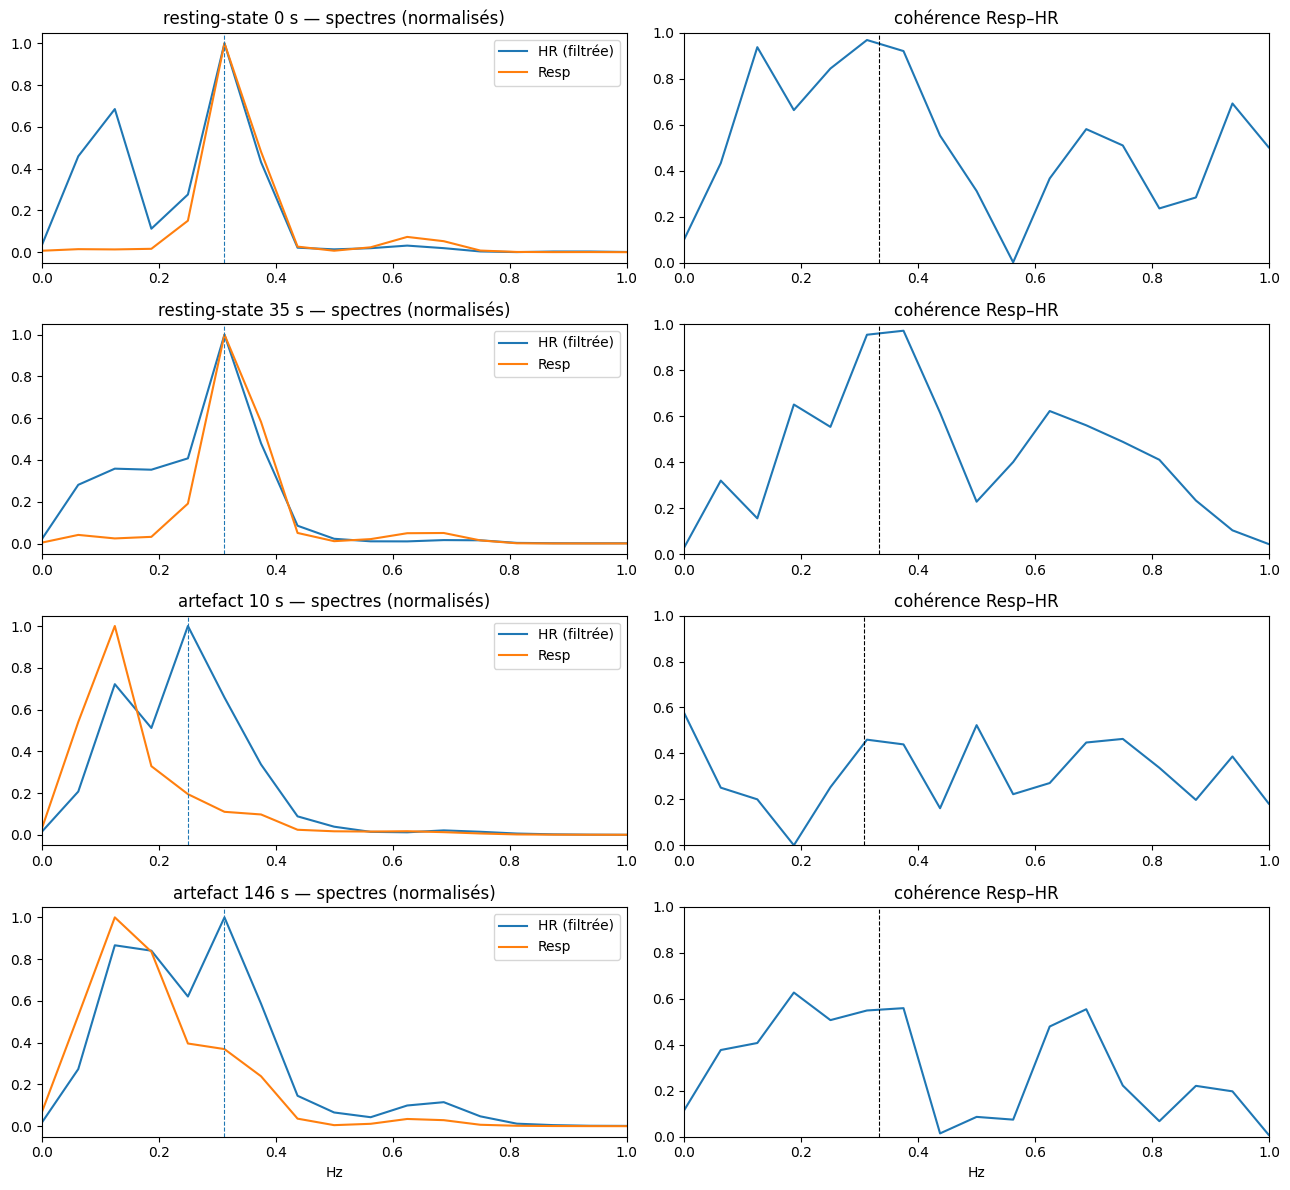

,task,on_s,f_resp_Hz,f_pic_HR_Hz,cohérence,délai_phase_s
0,resting-state,0.000,0.333,0.312,0.969,0.884
1,resting-state,35.078,0.333,0.312,0.954,0.766
2,artefact,9.928,0.308,0.250,0.460,0.784
3,artefact,145.533,0.333,0.312,0.549,0.662


In [47]:
rows = []
fig, axs = plt.subplots(len(win), 2, figsize=(13, 3 * len(win)))
for ax, ((task, on), (t_w, hr_w, resp_w)) in zip(axs, win.items()):
    # 3. Spectres
    f_hr, p_hr = spectrum(hr_w)
    f_rs, p_rs = spectrum(resp_w)
    f_pk, _ = band_peak(f_hr, p_hr)                   # pic de HR dans 0,15–0,5 Hz
    pk, _ = breath_cycles(resp_w, fs=FS_HR)           # fréquence respiratoire par les cycles
    f_resp = 1 / np.median(np.diff(pk) / FS_HR)       # (le pic du spectre Resp est piégé par les soupirs)
    ax[0].plot(f_hr, p_hr / p_hr.max(), label="HR (filtrée)")
    ax[0].plot(f_rs, p_rs / p_rs.max(), label="Resp")
    ax[0].axvline(f_pk, ls="--", color="C0", lw=.8)
    ax[0].set_xlim(0, 1); ax[0].set_title(f"{task} {on:.0f} s — spectres (normalisés)"); ax[0].legend()

    # 4. Cohérence et phase à la fréquence respiratoire
    f_c, coh, phase = resp_hr_coherence(resp_w, hr_w)
    i = np.argmin(np.abs(f_c - f_resp))               # case de fréquence la plus proche de f_resp
    ax[1].plot(f_c, coh); ax[1].axvline(f_resp, ls="--", color="k", lw=.8)
    ax[1].set_xlim(0, 1); ax[1].set_ylim(0, 1); ax[1].set_title("cohérence Resp–HR")
    rows.append({"task": task, "on_s": on, "f_resp_Hz": f_resp, "f_pic_HR_Hz": f_pk,
                 "cohérence": coh[i], "délai_phase_s": phase[i] / (2 * np.pi * f_c[i])})
for a in axs[-1]: a.set_xlabel("Hz")
plt.tight_layout(); plt.show()
coupling = pd.DataFrame(rows).round(3)
coupling

**Constats (P001)** — à vérifier sur ta figure :
- **Couplage présent** : le pic de HR filtrée tombe sur la fréquence respiratoire (~0,31–0,33 Hz) dans 3 fenêtres sur 4 (0,25 Hz pour artefact 10 s).
- **Cohérence** très forte en resting-state (~0,95–0,97), modérée dans les fenêtres de l'artefact (~0,46–0,55), plus perturbées par les soupirs.
- **Délai par la phase** : HR en retard de ~0,7–0,9 s sur l'inspiration, cohérent sur les 4 fenêtres. Approximatif (case de fréquence ~0,06 Hz) → à confronter à `latence()` en 1.5.

➡️ Prochaine sous-étape : **1.5 Délai** avec `latence()` (HR filtrée vs Resp, `max_lag_s` ≤ ½ période respiratoire ≈ 1,5 s).

## 1.5 — Délai Resp → HR avec `latence()`

**Convention** : `latence(resp, hr, ...)` renvoie un délai **positif si HR est en retard sur Resp**. Vérifié ci-dessous sur un signal synthétique.

Trois réglages importants :
1. **Résolution** : à 4 Hz, les délais testés vont par pas de 0,25 s, trop grossier pour un délai attendu < 1 s. On reconstruit HR et Resp sur une grille à **20 Hz** (pas de 50 ms). Interpoler HR plus finement n'invente pas d'information, mais permet de localiser le pic de corrélation plus précisément.
2. **`max_lag_s` = 1,5 s** : la respiration a une période d'environ 3 s. Au-delà d'une demi-période, le cycle voisin ressemble autant que le bon → délai ambigu.
3. **`sign=+1`** : le comportement d'origine prend le plus grand **|corrélation|**. Or pour un signal périodique, il existe aussi un pic **négatif** à environ ±½ période du bon. Sur P001, il est presque aussi haut (−0,61 contre +0,70) : avec `abs`, on risque de tomber dessus. La physiologie fixe le signe : HR monte à l'inspiration (Resp positive = inspiration) → on cherche une corrélation **positive**. J'ai ajouté le paramètre `sign` à `latence()` ; sans lui (`sign=None`), elle se comporte comme avant.

In [50]:
# Vérification de la convention de signe : HR synthétique en retard de 0,5 s
t = np.arange(0, 60, 1 / 20)
resp_syn = np.sin(2 * np.pi * 0.3 * t)
hr_syn = np.sin(2 * np.pi * 0.3 * (t - 0.5))
print("délai attendu +0,5 s →", latence(resp_syn, hr_syn, 20, max_lag_s=1.5, sign=+1))

délai attendu +0,5 s → (np.float64(0.5), np.float64(0.9953133791767941))


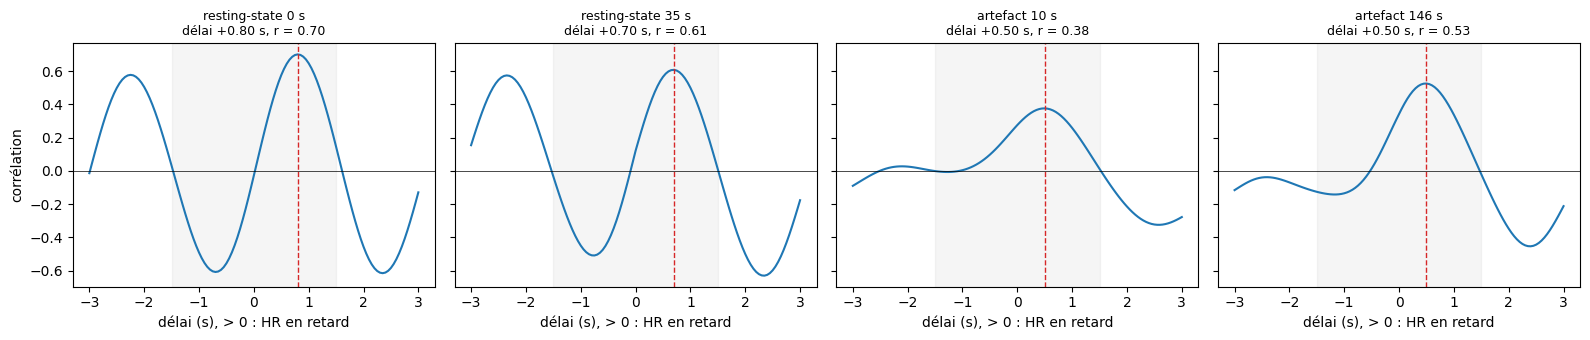

,task,on_s,délai_xcorr_s,r,délai_abs_s,r_abs,cohérence,délai_phase_s
0,resting-state,0,0.8,0.70,0.8,0.70,0.97,0.88
1,resting-state,35,0.7,0.61,0.7,0.61,0.95,0.77
2,artefact,10,0.5,0.38,0.5,0.38,0.46,0.78
3,artefact,146,0.5,0.53,0.5,0.53,0.55,0.66


In [51]:
FS_LAG = 20.0    # Hz, grille fine pour la cross-corrélation
MAX_LAG = 1.5    # s, ≤ ½ période respiratoire
segs = {"resting-state": rest, "artefact": art}

# Mêmes fenêtres que win, reconstruites à 20 Hz
win20 = {}
for task, df in segs.items():
    t_hr, h = hr_series(rpk[task], len(df), fs_out=FS_LAG)
    h_f = hr_fast(h, fs=FS_LAG)
    for on, off, txt in task_windows(task):
        if not txt.startswith("repos"):
            continue
        t_w, hr_w = crop(t_hr, h_f, on, off)
        win20[(task, on)] = (t_w, hr_w, on_grid(resp_insp[task], t_w))

rows = []
fig, axs = plt.subplots(1, len(win20), figsize=(16, 3.5), sharey=True)
for ax, ((task, on), (t_w, hr_w, resp_w)) in zip(axs, win20.items()):
    lag, r = latence(resp_w, hr_w, FS_LAG, max_lag_s=MAX_LAG, sign=+1)
    lag_abs, r_abs = latence(resp_w, hr_w, FS_LAG, max_lag_s=MAX_LAG)       # comportement d'origine
    # courbe complète, pour voir le pic positif et le pic négatif
    x = (resp_w - resp_w.mean()) / resp_w.std(); y = (hr_w - hr_w.mean()) / hr_w.std()
    cc = correlate(y, x) / len(x); L = correlation_lags(len(y), len(x)) / FS_LAG
    k = np.abs(L) <= 3
    ax.plot(L[k], cc[k]); ax.axvspan(-MAX_LAG, MAX_LAG, color="grey", alpha=.08)
    ax.axvline(lag, color="C3", ls="--", lw=1); ax.axhline(0, color="k", lw=.5)
    ax.set_title(f"{task} {on:.0f} s\ndélai {lag:+.2f} s, r = {r:.2f}", fontsize=9); ax.set_xlabel("délai (s), > 0 : HR en retard")
    rows.append({"task": task, "on_s": round(on), "délai_xcorr_s": lag, "r": r,
                 "délai_abs_s": lag_abs, "r_abs": r_abs})
axs[0].set_ylabel("corrélation")
plt.tight_layout(); plt.show()

delays = pd.DataFrame(rows).merge(coupling[["task", "on_s", "cohérence", "délai_phase_s"]].assign(on_s=lambda d: d.on_s.round().astype(int)),
                                  on=["task", "on_s"]).round(2)
delays

**Constats (P001)** — à vérifier sur ta figure et le tableau :
- **Délai** : HR en retard de **+0,5 à +0,8 s** sur l'inspiration, sur les 4 fenêtres (pic positif, r ≈ 0,4–0,7). Même sens et même ordre de grandeur que le délai par la phase (1.4, +0,66 à +0,88 s) — deux méthodes indépendantes concordent.
- **Pic négatif** à environ −0,7 s, presque aussi haut en resting-state (≈ −0,5/−0,6) : c'est le piège évité par `sign=+1`. Ici `abs` donne le même résultat, mais ce ne sera pas garanti partout.
- Les fenêtres de l'artefact (soupirs, cohérence plus faible) donnent un délai un peu plus court et une corrélation plus faible.
- Plausibilité biologique : la RSA passe par le nerf vague, dont l'effet sur le cœur se fait en moins d'une seconde → un délai de ~0,5–0,8 s est compatible.

➡️ Prochaine sous-étape : **1.6 Contrôles** (décalage artificiel connu, surrogates, stabilité, CURATED vs PREPROCESSED).